In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df_sales = pd.read_csv('Ecommerce.csv',encoding='latin1')
df_sales

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,12/9/2011 12:50,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,12/9/2011 12:50,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,12/9/2011 12:50,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,12/9/2011 12:50,4.15,12680.0,France


In [2]:
df_sales.isna().any()


InvoiceNo      False
StockCode      False
Description     True
Quantity       False
InvoiceDate    False
UnitPrice      False
CustomerID      True
Country        False
dtype: bool

In [3]:
df_sales.isna().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [4]:
df_sales.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


In [5]:
#Filas que tienen valores NaN en cualquier columna:
df_sales[df_sales.isna().any(axis=1)]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,12/1/2010 11:52,0.00,NaN,United Kingdom
1443,536544,21773,DECORATIVE ROSE BATHROOM BOTTLE,1,12/1/2010 14:32,2.51,NaN,United Kingdom
1444,536544,21774,DECORATIVE CATS BATHROOM BOTTLE,2,12/1/2010 14:32,2.51,NaN,United Kingdom
1445,536544,21786,POLKADOT RAIN HAT,4,12/1/2010 14:32,0.85,NaN,United Kingdom
1446,536544,21787,RAIN PONCHO RETROSPOT,2,12/1/2010 14:32,1.66,NaN,United Kingdom
...,...,...,...,...,...,...,...,...
541536,581498,85099B,JUMBO BAG RED RETROSPOT,5,12/9/2011 10:26,4.13,NaN,United Kingdom
541537,581498,85099C,JUMBO BAG BAROQUE BLACK WHITE,4,12/9/2011 10:26,4.13,NaN,United Kingdom
541538,581498,85150,LADIES & GENTLEMEN METAL SIGN,1,12/9/2011 10:26,4.96,NaN,United Kingdom
541539,581498,85174,S/4 CACTI CANDLES,1,12/9/2011 10:26,10.79,NaN,United Kingdom


In [6]:
# dataframe con datos limpios sin NaN solo en la columna de cliente

df_sales['Quantity'] = df_sales['Quantity'].astype('int64')
#Convierto a String, astype(str) esta es otra forma pero al usar info muestra object

df_sales[['InvoiceNo','StockCode','Description','Country']] = df_sales[['InvoiceNo','StockCode','Description','Country']].astype('string')

df_sales['InvoiceDate'] = pd.to_datetime(df_sales['InvoiceDate'])

df_sales.info()



#df_sales['Description'] = df_clientes['Description'].fillna('Sin descripción') #para los que tienen descripción Nan rellena con Sin descripción

#df_sales_cleaned = df.dropna(subset=['CustomerID']) # Borra solo las filas donde falte el ID del cliente




<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  string        
 1   StockCode    541909 non-null  string        
 2   Description  540455 non-null  string        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  string        
dtypes: datetime64[ns](1), float64(2), int64(1), string(4)
memory usage: 33.1 MB


In [7]:
#Quitamos los espacios en blanco a los nomnbres de las columnas
df_sales.columns = df_sales.columns.str.strip()

#Crea una columna con las ventas totales, precio unitario * valor unitario
df_sales['TotalPrice'] = df_sales['Quantity'] * df_sales['UnitPrice']

#Elimina los NaN de clientes sin Identificarabs
df_sales_cleaned = df_sales.dropna(subset=['CustomerID']).copy()

In [8]:
df_sales.info


<bound method DataFrame.info of        InvoiceNo StockCode                          Description  Quantity  \
0         536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1         536365     71053                  WHITE METAL LANTERN         6   
2         536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3         536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4         536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   
...          ...       ...                                  ...       ...   
541904    581587     22613          PACK OF 20 SPACEBOY NAPKINS        12   
541905    581587     22899         CHILDREN'S APRON DOLLY GIRL          6   
541906    581587     23254        CHILDRENS CUTLERY DOLLY GIRL          4   
541907    581587     23255      CHILDRENS CUTLERY CIRCUS PARADE         4   
541908    581587     22138        BAKING SET 9 PIECE RETROSPOT          3   

               InvoiceDate  UnitPrice  Cust

In [9]:
df_sales_cleaned.info

<bound method DataFrame.info of        InvoiceNo StockCode                          Description  Quantity  \
0         536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1         536365     71053                  WHITE METAL LANTERN         6   
2         536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3         536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4         536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   
...          ...       ...                                  ...       ...   
541904    581587     22613          PACK OF 20 SPACEBOY NAPKINS        12   
541905    581587     22899         CHILDREN'S APRON DOLLY GIRL          6   
541906    581587     23254        CHILDRENS CUTLERY DOLLY GIRL          4   
541907    581587     23255      CHILDRENS CUTLERY CIRCUS PARADE         4   
541908    581587     22138        BAKING SET 9 PIECE RETROSPOT          3   

               InvoiceDate  UnitPrice  Cust

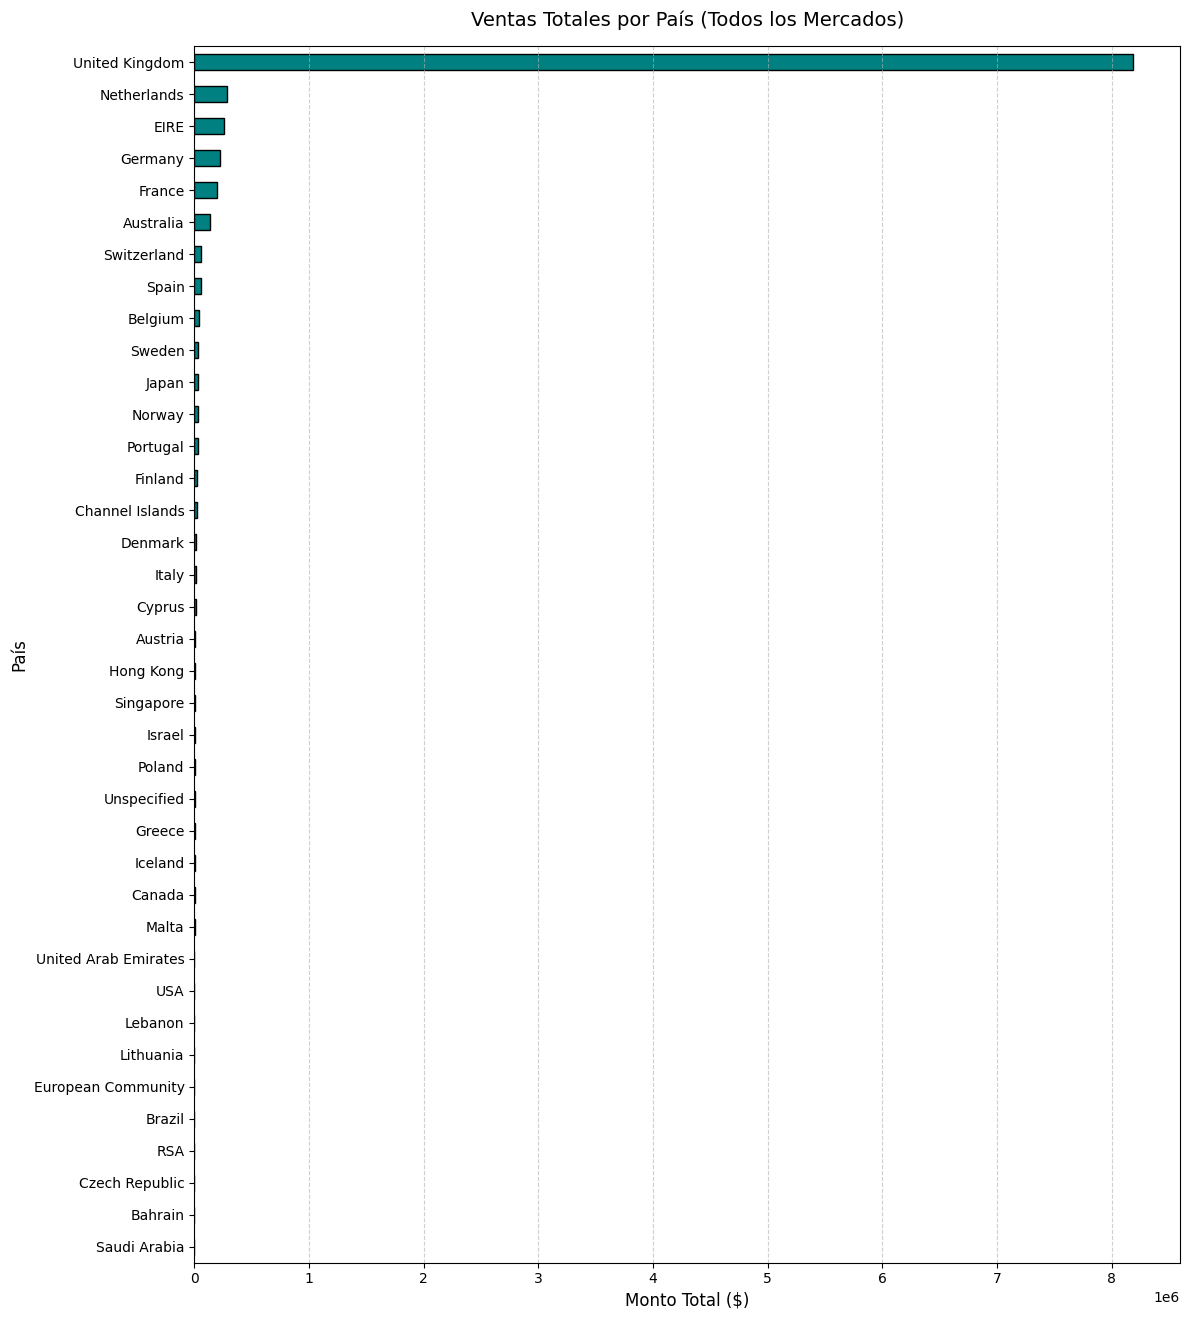

In [10]:
# Grafica de ventas por paises, agrupados de mayor a menor
ventas_todos = df_sales.groupby('Country')['TotalPrice'].sum().sort_values(ascending=True)

# Gráfica con altura dinámica basada en la cantidad de países
plt.figure(figsize=(12, len(ventas_todos) * 0.35))

#Graficar
ventas_todos.plot(kind='barh', color='teal', edgecolor='black')

plt.title('Ventas Totales por País (Todos los Mercados)', fontsize=14, pad=15)
plt.xlabel('Monto Total ($)', fontsize=12)
plt.ylabel('País', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

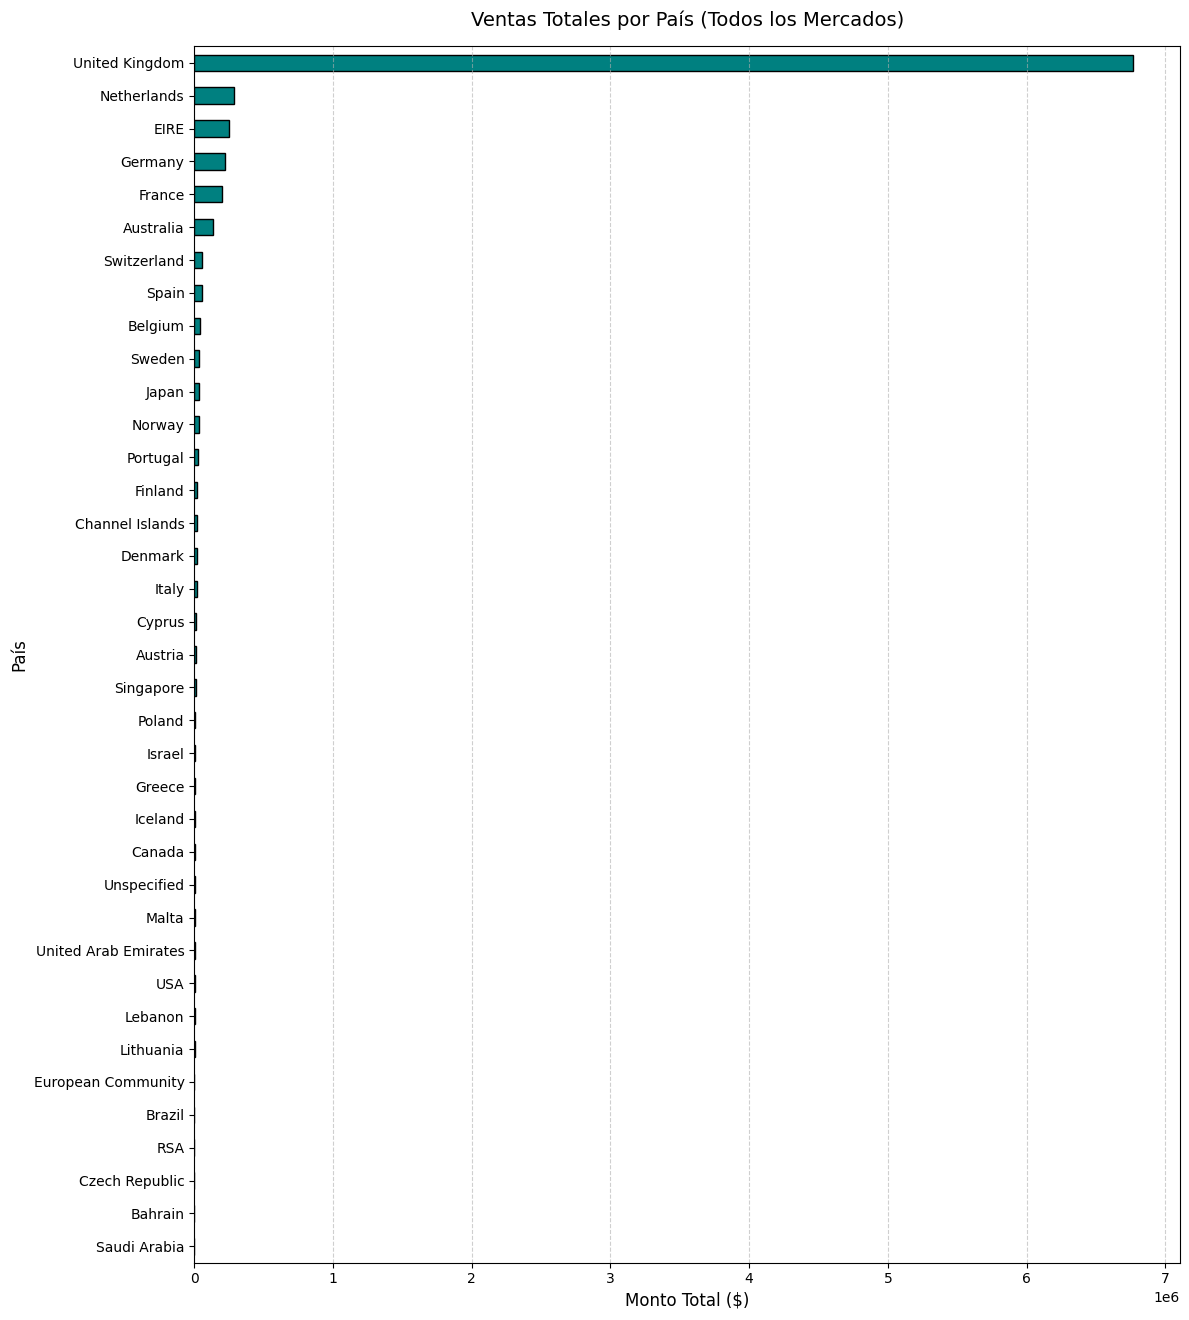

In [11]:
# Grafica de ventas por paises, agrupados de mayor a menor
ventas_sin_cliente = df_sales_cleaned.groupby('Country')['TotalPrice'].sum().sort_values(ascending=True)

# Gráfica con altura dinámica basada en la cantidad de países
plt.figure(figsize=(12, len(ventas_todos) * 0.35))

#Graficar
ventas_sin_cliente.plot(kind='barh', color='teal', edgecolor='black')

plt.title('Ventas Totales por País (Todos los Mercados)', fontsize=14, pad=15)
plt.xlabel('Monto Total ($)', fontsize=12)
plt.ylabel('País', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig('Vtas_Totales_Por_Pais.png', dpi=300, bbox_inches='tight')

plt.show()



In [12]:
#Transacciones sin customer ID
total_registros = len(df_sales)

#Cantidad de registros sin cliente Customer_id NAN
sin_id_cliente = df_sales['CustomerID'].isna().sum()

#Porcentaje de Nulos
porcentaje_nulos = (sin_id_cliente/total_registros)*100

print(f"Total de registros: {total_registros:,}")
print(f"Total de registros sin cliente: {sin_id_cliente:,}")
print(f"Porcentaje de registros sin cliente: {porcentaje_nulos:,} ({porcentaje_nulos:.2f}%)")
#print(f"Registros sin CustomerID: {nulos_customer:,} ({porcentaje_nulos:.2f}%)")

                                                             

Total de registros: 541,909
Total de registros sin cliente: 135,080
Porcentaje de registros sin cliente: 24.926694334288598 (24.93%)


<Figure size 800x600 with 0 Axes>

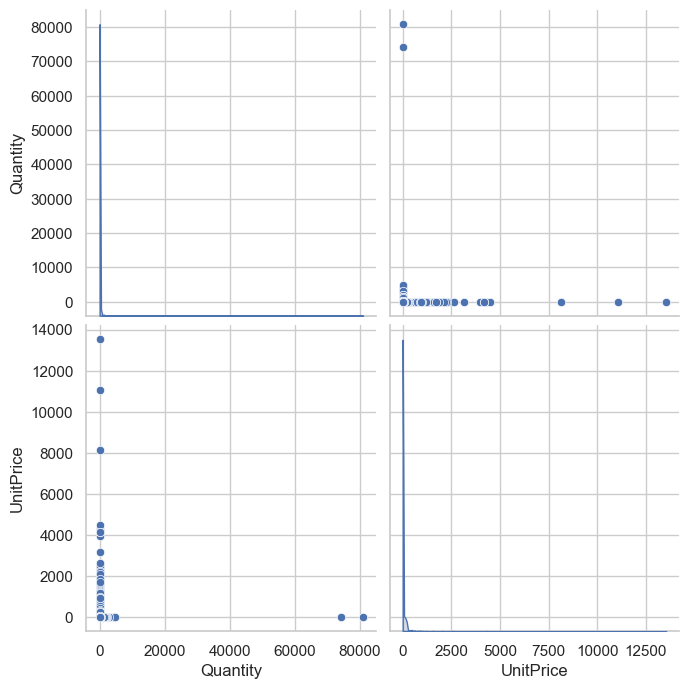

In [13]:
import seaborn as sns 

#Estilo profesional de seaborn
sns.set_theme(style="whitegrid")

#Evitamos que algún valor negativo afecte nuestro grafico
df_eda = df_sales[(df_sales['Quantity']>0) & (df_sales['UnitPrice']>0)]

#El dataset es muy pesado para la pc, vamos a manejar una muestra. 
#df_eda = df_eda.sample(n=10000, random_state=42) 

#Generar el pairplot con Quantity y Unitpriceab
plt.figure(figsize=(8,6))
sns.pairplot(df_eda[['Quantity','UnitPrice']], diag_kind='kde',height=3.5)
plt.show
plt.savefig('pairplot_resultados.png', dpi=300, bbox_inches='tight')

In [14]:
import os

print(os.path.abspath("pairplot_resultados.png"))

C:\Users\Alei\pry_Ecommerce\pairplot_resultados.png


Límite superior dinámico para Quantity (P99.5): 160.00
Límite superior dinámico para UnitPrice (P99.5): 24.96
Registros analizados tras el filtro dinámico: 525,236


<Figure size 800x600 with 0 Axes>

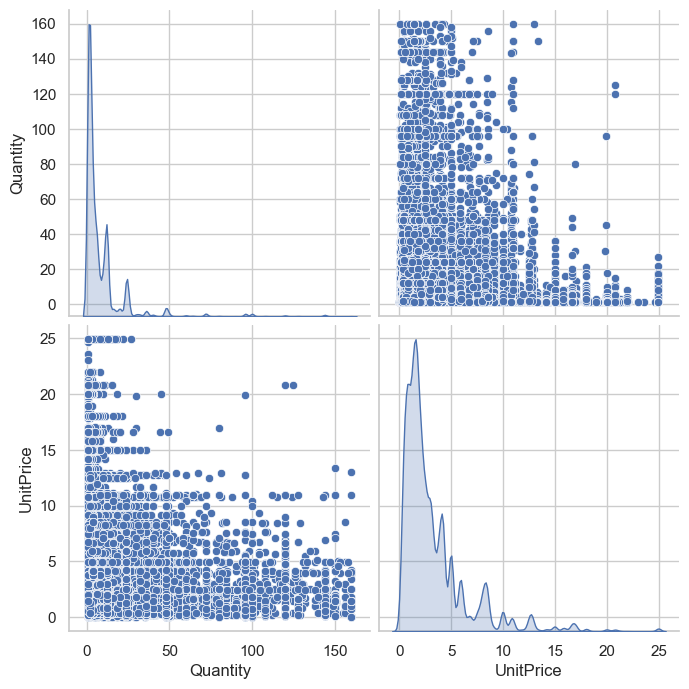

In [15]:
import matplotlib.pyplot as plt

#Descarta o elimina valores no validos o iguales a cero 
#.copy() crea un objeto independiente que no afecta el Dataframe inicial
df_clean = df_sales[(df_sales['Quantity']>0) & (df_sales['UnitPrice']>0)].copy()

#Calculo de percentiles altos para quitar los outliers más altos de forma dinamica, en este caso (99,5%)
q_qty = df_clean['Quantity'].quantile(0.995)
q_price = df_sales['UnitPrice'].quantile(0.995)

df_filtered = df_clean[
              (df_clean['Quantity'] <= q_qty) &
              (df_clean['UnitPrice']<=q_price)
]

print(f"Límite superior dinámico para Quantity (P99.5): {q_qty:.2f}")
print(f"Límite superior dinámico para UnitPrice (P99.5): {q_price:.2f}")
print(f"Registros analizados tras el filtro dinámico: {len(df_filtered):,}")

#Generación del pair plotabs
plt.figure(figsize=(8,6))
sns.pairplot(df_filtered[['Quantity','UnitPrice']],diag_kind='kde', height=3.5)


# Guardado de imagen
plt.savefig('pairplot_limpio_dinamico.png', dpi=300, bbox_inches='tight')
plt.show()


In [16]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# 1. Define variables (X = Predictor / Variable Independiente, y = Objetivo / Variable Dependiente)

X = df_filtered[['UnitPrice']]
y = df_filtered ['Quantity']

# 2. Divide los datos en conjuntos de entrenamiento (80%) y prueba (20%) para evaluar el modelo de forma rigurosa

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Inicializa y entrenar el modelo de Regresión Lineal
model = LinearRegression()
model.fit(X_train, y_train)

# 4. Genera predicciones sobre el conjunto de prueba
y_pred = model.predict(X_test)

# 5. Evalua el rendimiento del modelo
r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print(f"--- RESULTADOS DEL MODELO DE REGRESIÓN LINEAL ---")
print(f"Coeficiente (Pendiente - Slope): {model.coef_[0]:.4f}")
print(f"Intersección (Intercept): {model.intercept_:.4f}")
print(f"Coeficiente de Determinación (R²): {r2:.4f}")
print(f"Error Cuadrático Medio (RMSE): {rmse:.4f}")




--- RESULTADOS DEL MODELO DE REGRESIÓN LINEAL ---
Coeficiente (Pendiente - Slope): -1.0269
Intersección (Intercept): 11.7892
Coeficiente de Determinación (R²): 0.0488
Error Cuadrático Medio (RMSE): 14.6538


--- TOP 10 PAÍSES POR INGRESOS TOTALES ---
       Country  TotalPrice
United Kingdom 7341940.064
          EIRE  233252.520
       Germany  223125.340
   Netherlands  197251.570
        France  192614.530
     Australia   95039.630
   Switzerland   53004.420
         Spain   46711.910
       Belgium   40914.700
        Norway   31730.700


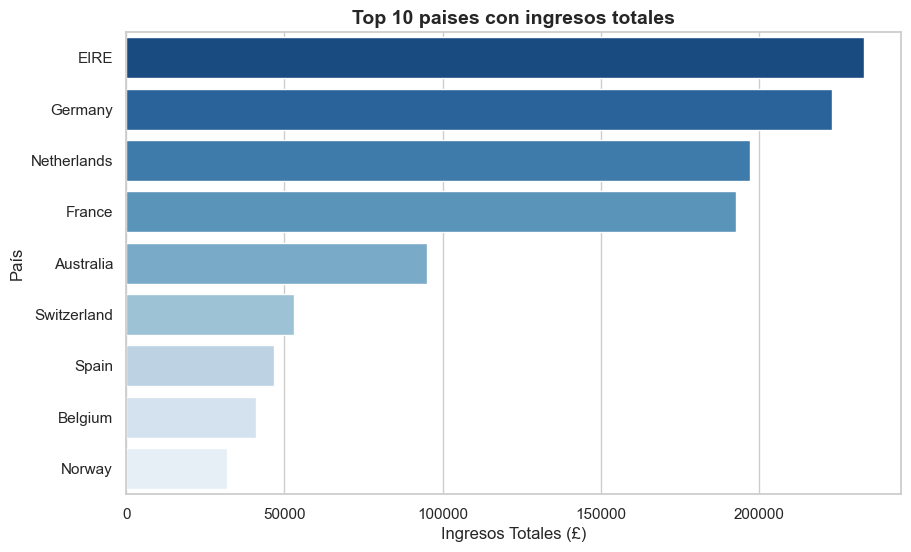

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Ingeniería de caracterísicas para determinar los consumos por país
df_filtered = df_filtered.copy()
df_filtered['TotalPrice']=df_filtered['Quantity'] * df_filtered['UnitPrice']


# 2. Análisis de ventas_por_paissis Ingresos por País (Top 10 países con mayores ventas)
ventas_por_pais = df_filtered.groupby('Country')['TotalPrice'].sum().reset_index()
ventas_por_pais = ventas_por_pais.sort_values(by='TotalPrice',ascending=False).head(10)


print("--- TOP 10 PAÍSES POR INGRESOS TOTALES ---")
print(ventas_por_pais.to_string(index=False))

# 3. Grafico de barras, excluimos a UK para optimizar la visualización
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

# 4. Acá puedo exluir a UK
ventas_sin_UK = ventas_por_pais[ventas_por_pais['Country'].str.strip() != 'United Kingdom']


sns.barplot(
   data = ventas_sin_UK,
   hue='Country',  # Especifica que variable controla la paleta de colores. En esta caso cada país tiene un color
    x='TotalPrice', 
    y='Country', 
    palette='Blues_r',
    legend=False,  # <-Evitar la leyenda repetida
)

plt.title('Top 10 paises con ingresos totales',fontsize=14, fontweight='bold')
plt.xlabel('Ingresos Totales (£)', fontsize=12)
plt.ylabel('País', fontsize=12)


# Guardar la gráfica para el repositorio
plt.savefig('ingresos_por_pais.png', dpi=300, bbox_inches='tight')
plt.show()

In [18]:
# Exporta el DataFrame filtrado y con la columna TotalPrice a un archivo CSV
output_filename = 'online_retail_clean_powerbi.csv'

df_filtered.to_csv(output_filename, index=False, encoding='utf-8')

print(f"¡Dataset exportado con éxito como '{output_filename}'!")
print(f"Total de registros listos para Power BI: {len(df_filtered):,}")

¡Dataset exportado con éxito como 'online_retail_clean_powerbi.csv'!
Total de registros listos para Power BI: 525,236


In [19]:
# Exporta utilizando con coma: separador decimal y punto y coma: como separador de campos
df_filtered.to_csv('online_retail_clean_powerbi_cp.csv', index=False, sep=';', decimal=',', encoding='utf-8')
print("¡Archivo re-exportado con formato internacional estándar!")

¡Archivo re-exportado con formato internacional estándar!


In [20]:
import datetime as dt

# 1. Definimos la fecha de referencia (1 día después de la última venta registrada)
snapshot_date = df_filtered['InvoiceDate'].max() + dt.timedelta(days=1)

# 2. Agrupa por CustomerID para calcular Recency, Frequency y Monetary
rfm = df_filtered.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (snapshot_date - x.max()).days, # Días desde última compra
    'InvoiceNo': 'nunique',                                  # Pedidos únicos
    'TotalPrice': 'sum'                                      # Total gastado
}).reset_index()

# 3. Renombra las columnas
rfm.columns = ['CustomerID', 'Recency', 'Frequency', 'Monetary']

print("Primeros registros RFM:")
print(rfm.head())

Primeros registros RFM:
   CustomerID  Recency  Frequency  Monetary
0     12347.0        2          7   4060.40
1     12348.0       75          4   1437.24
2     12349.0       19          1   1417.60
3     12350.0      310          1    294.40
4     12352.0       36          7   1385.74


In [29]:
# Creación de etiquetas de puntuación
r_labels = range(4, 0, -1) # Cuanto menor sea la recesión (menos días), mejor puntuación (4)
f_labels = range(1, 5)    # Mayor frecuencia, mejor puntuación (4)
m_labels = range(1, 5)    # Mayor gasto, mejor puntuación (4)

# Asignación de scores
rfm['R_Score'] = pd.qcut(rfm['Recency'], q=4, labels=r_labels)
# NOTA: Para Frecuencia usamos rank(method='first') si hay muchos valores duplicados
rfm['F_Score'] = pd.qcut(rfm['Frequency'].rank(method='first'), q=4, labels=f_labels)
rfm['M_Score'] = pd.qcut(rfm['Monetary'], q=4, labels=m_labels)

# Concatena para obtener la puntuación combinada y la suma total
rfm['RFM_Segment'] = rfm['R_Score'].astype(str) + rfm['F_Score'].astype(str) + rfm['M_Score'].astype(str)
rfm['RFM_Score'] = rfm[['R_Score', 'F_Score', 'M_Score']].sum(axis=1)

print(rfm.head())

   CustomerID  Recency  Frequency  Monetary R_Score F_Score M_Score  \
0     12347.0        2          7   4060.40       4       4       4   
1     12348.0       75          4   1437.24       2       3       3   
2     12349.0       19          1   1417.60       3       1       3   
3     12350.0      310          1    294.40       1       1       1   
4     12352.0       36          7   1385.74       3       4       3   

  RFM_Segment  RFM_Score  
0         444         12  
1         233          8  
2         313          7  
3         111          3  
4         343         10  


In [70]:
def segmentar_cliente(df):
  if df['RFM_Score'] >= 10:
     return 'Champions / VIP'
  elif (df['RFM_Score'] >= 7) and (df['RFM_Score'] < 10):
     return 'Leales'
  elif (df['RFM_Score'] >= 5) and (df['RFM_Score'] < 7):
     return 'En Riesgo / En Necesidad de Atención'
  else:
     return 'Inactivos / Perdidos'

rfm['Segmento'] = rfm.apply(segmentar_cliente, axis=1)

# Ver distribución de clientes por segmento
print(rfm['Segmento'].value_counts())

Segmento
Leales                                  1263
Champions / VIP                         1250
En Riesgo / En Necesidad de Atención     993
Inactivos / Perdidos                     796
Name: count, dtype: int64


In [71]:
# Une la columna de Segmento al dataframe filtrado
df_filtered_rfm = df_filtered.merge(rfm[['CustomerID', 'Segmento', 'RFM_Score']], on='CustomerID', how='left')

# Exporta con el formato correcto para Power BI
df_filtered_rfm.to_csv('online_retail_clean_powerbi.csv', index=False, sep=';', decimal=',', encoding='utf-8')
print("¡Archivo con RFM exportado!")

¡Archivo enriquecido con RFM exportado con éxito!
